2.744468361693255


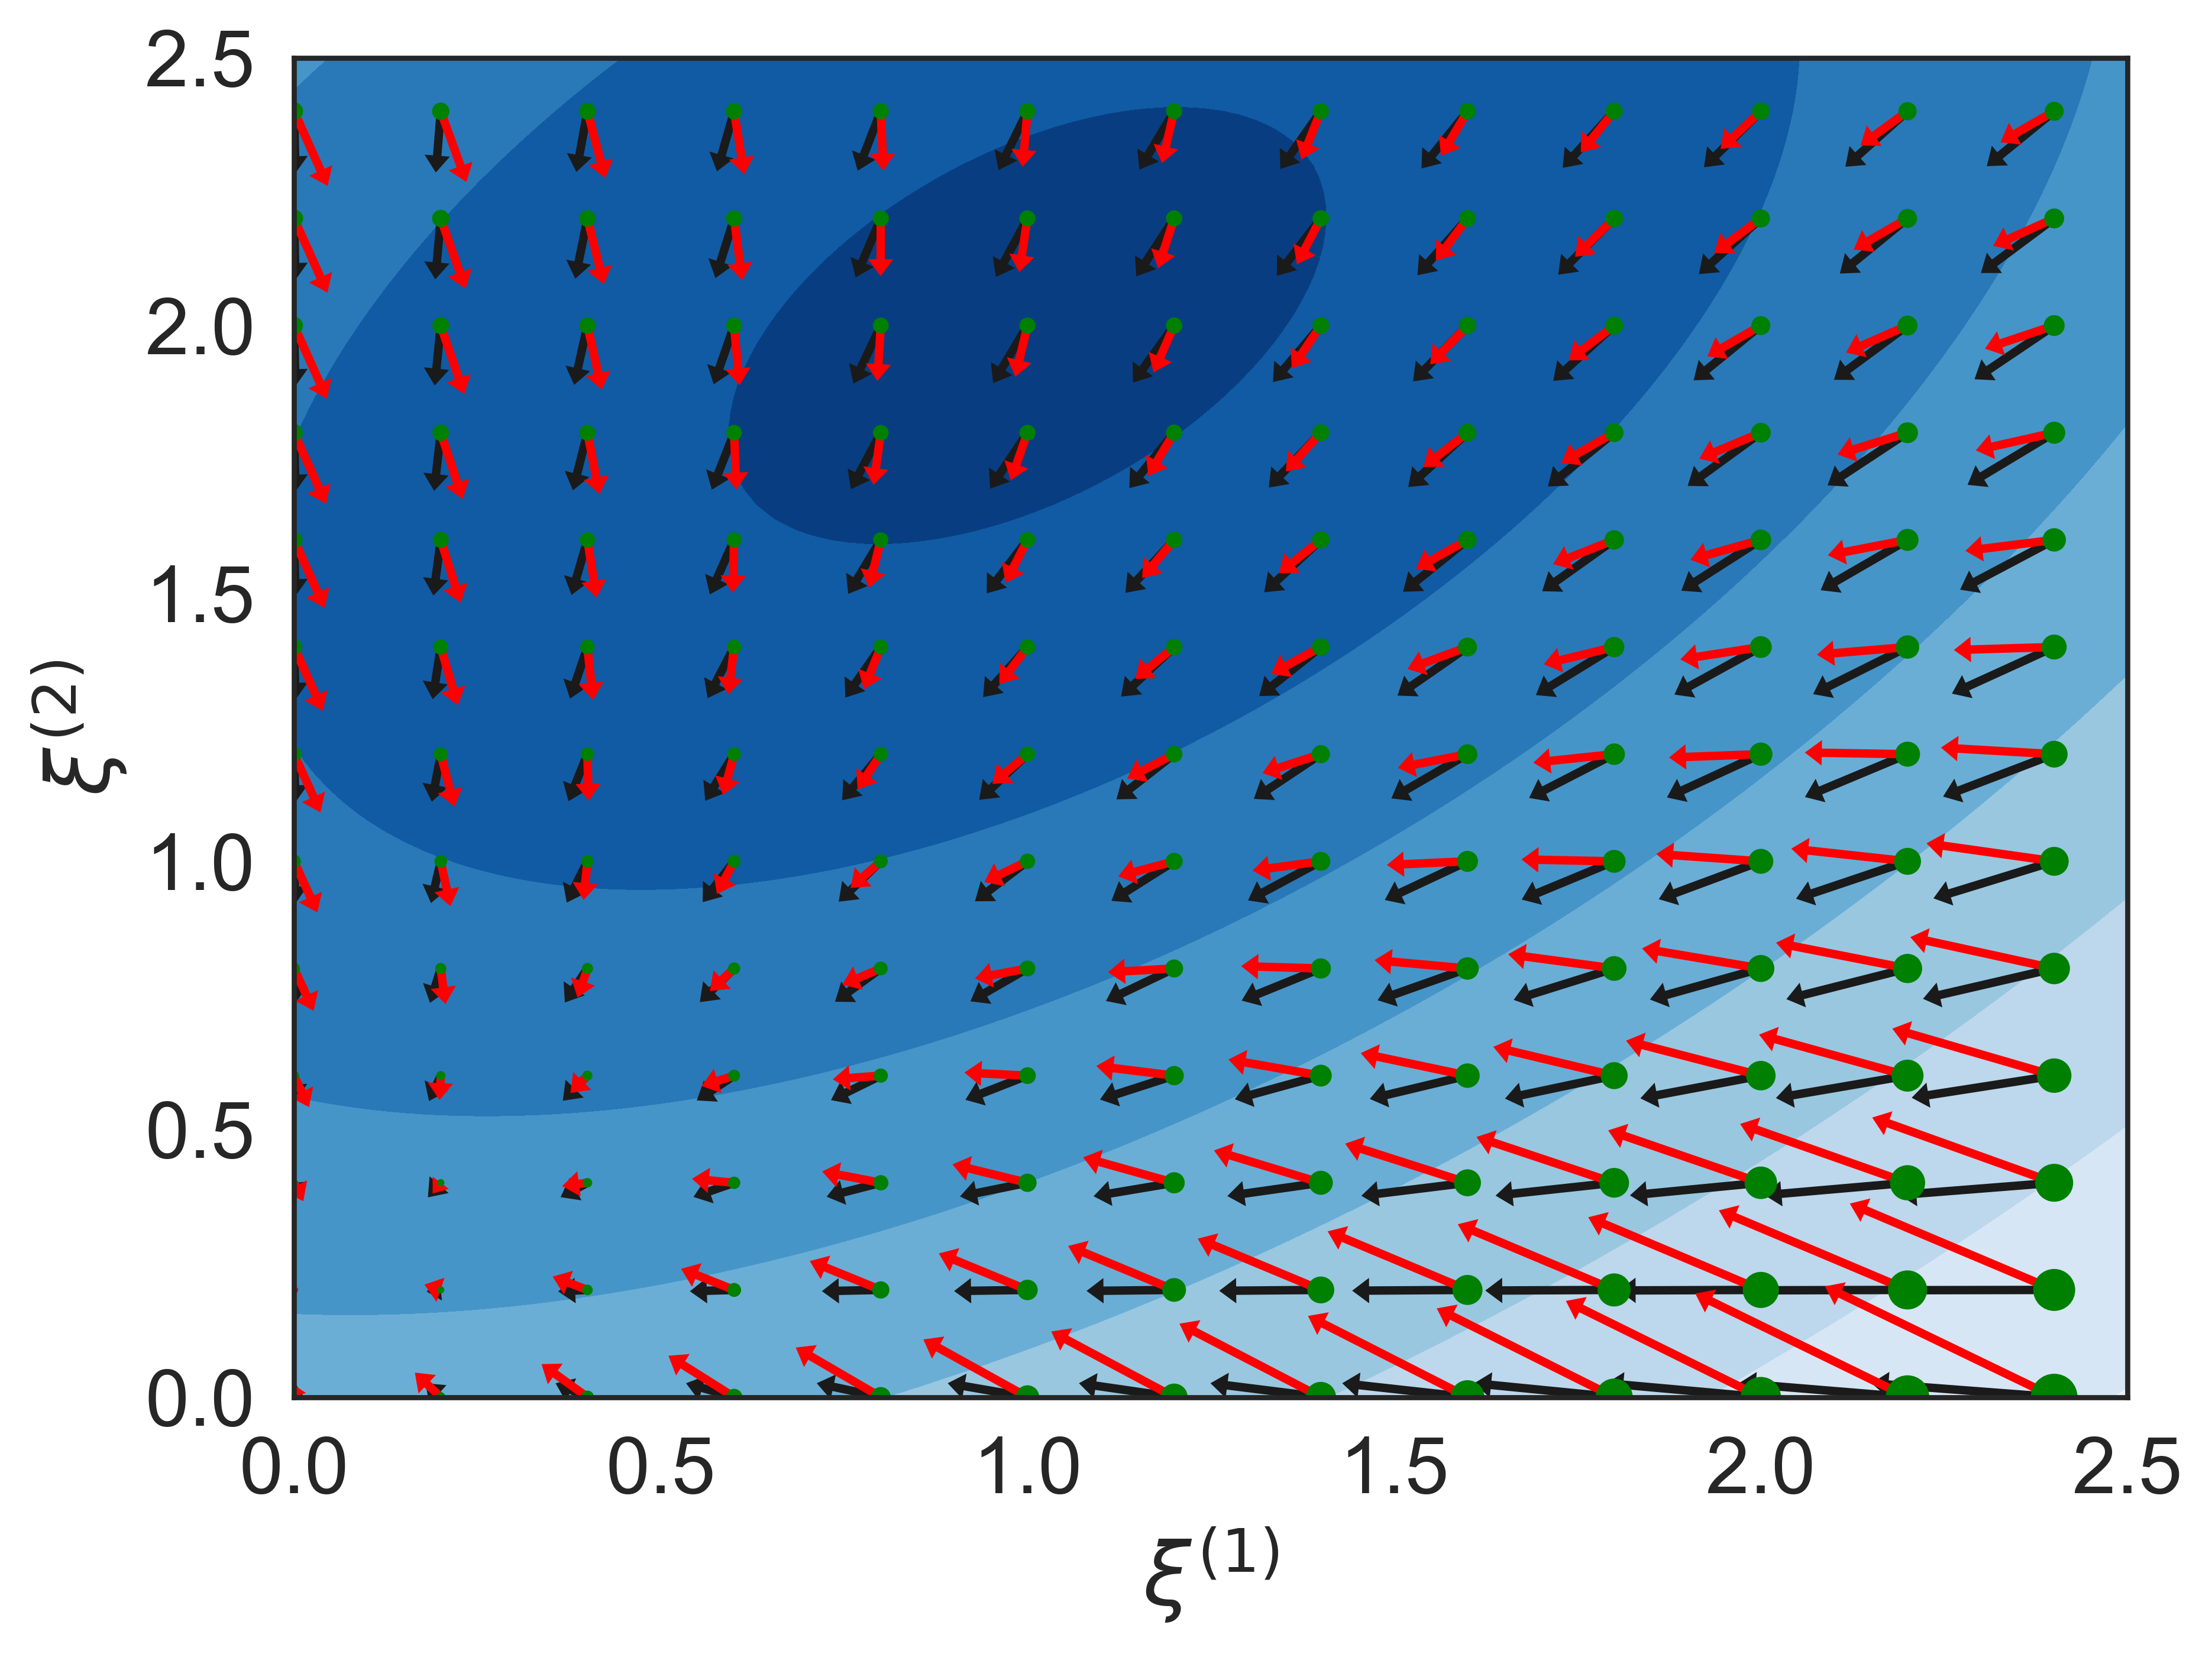

In [33]:
from pathlib import Path
import sys

# Find the repository when this notebook is opened from root or case_study.
_repo_root = next((p for p in (Path.cwd(), *Path.cwd().parents)
                   if (p / 'src' / 'paths.py').is_file()), None)
if _repo_root is None:
    raise RuntimeError('Run this notebook from within the repository directory.')
if str(_repo_root) not in sys.path:
    sys.path.insert(0, str(_repo_root))
from src.paths import figure_path

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib
import math

sns.set(style = 'white', font_scale = 1.75)
fig, ax = plt.subplots(figsize = (8, 6), dpi = 500)
plt.rc("axes.spines", top = False, right = False)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

# reference: https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.quiver.html

# Generate some example data

MC_num = 50000
mean = np.array([1, 2])
covariance = np.array([[4, 2], [2, 4]])


method = 'SAA'


if method == 'SAA':
    # Calculate influence function for each data point
    bestx = np.array([0.04, 0.41])
    ind_cov = np.eye(2)
    exp_term = math.exp(-np.dot(mean, bestx) + 0.5 * bestx.dot(covariance).dot(bestx))
    tilted_mean = mean - covariance.dot(bestx)
    exact_hessian = exp_term * (covariance + np.outer(tilted_mean, tilted_mean)) + 0.4 * ind_cov
    hessian_inv = np.linalg.inv(exact_hessian)
    def calculate_influence(pt):
        return -math.exp(-np.dot(pt, bestx)) * pt + 0.4 * bestx
        #np.array([pt[0] - mean[0], pt[1] - mean[1]])

    def calculate_grad(pt):
        grad = -math.exp(-np.dot(pt, bestx)) * pt + 0.4 * bestx
        return hessian_inv.dot(grad)
elif method == 'ETO':
    bestx = np.array([0.21, 0.42])

    def true_decision_param(theta, x):
        regularization = 0.4
        dim = len(x)
        a = -theta + 4 * x
        exp_term = math.exp(-np.dot(theta, x) + 2 * np.linalg.norm(x) ** 2)

        F_x = exp_term * (4 * np.eye(dim) + np.outer(a, a)) + regularization * np.eye(dim)
        F_theta = exp_term * (-np.eye(dim) - np.outer(a, x))
        return -np.linalg.solve(F_x, F_theta)

    decision_param = true_decision_param(mean, bestx)


    def calculate_influence(pt):
        return np.array([pt[0] - mean[0], pt[1] - mean[1]])

    def calculate_grad(pt):
        grad = -math.exp(-np.dot(pt, bestx)) * pt + 0.4 * bestx
        return -np.dot(decision_param, grad)
        
elif method == 'IEO':
    from scipy.optimize import root

    bestx = np.array([0.04, 0.41])
    theta_star = np.array([0.17, 1.92])

    def decision_equation(x, theta):
        exp_term = math.exp(-np.dot(theta, x) + 2 * np.linalg.norm(x) ** 2)
        return (-theta + 4 * x) * exp_term + 0.4 * x

    def solve_decision(theta, init_x=bestx):
        sol = root(lambda x: decision_equation(x, theta), init_x)
        if not sol.success:
            print(f"Warning: decision solve did not converge for theta={theta}: {sol.message}")
        return sol.x

    def true_decision_param(theta, x):
        regularization = 0.4
        dim = len(x)
        a = -theta + 4 * x
        exp_term = math.exp(-np.dot(theta, x) + 2 * np.linalg.norm(x) ** 2)

        F_x = exp_term * (4 * np.eye(dim) + np.outer(a, a)) + regularization * np.eye(dim)
        F_theta = exp_term * (-np.eye(dim) - np.outer(a, x))
        return -np.linalg.solve(F_x, F_theta)

    def expected_h(theta):
        x_star = solve_decision(theta)
        exp_term = math.exp(-np.dot(mean, x_star) + 0.5 * x_star.dot(covariance).dot(x_star))
        return exp_term + 0.2 * np.linalg.norm(x_star) ** 2

    def finite_diff_hessian(func, theta, eps=1e-4):
        dim = len(theta)
        hessian = np.zeros((dim, dim))
        f0 = func(theta)
        for i in range(dim):
            ei = np.zeros(dim)
            ei[i] = eps
            hessian[i, i] = (func(theta + ei) - 2 * f0 + func(theta - ei)) / eps ** 2
            for j in range(i + 1, dim):
                ej = np.zeros(dim)
                ej[j] = eps
                hessian[i, j] = (func(theta + ei + ej) - func(theta + ei - ej) - func(theta - ei + ej) + func(theta - ei - ej)) / (4 * eps ** 2)
                hessian[j, i] = hessian[i, j]
        return hessian

    decision_param = true_decision_param(theta_star, bestx)
    theta_hessian = finite_diff_hessian(expected_h, theta_star)
    theta_hessian_inv = np.linalg.pinv(theta_hessian)

    def calculate_grad(pt):
        grad_x_h = -math.exp(-np.dot(pt, bestx)) * pt + 0.4 * bestx
        return -decision_param.T.dot(grad_x_h)

    def calculate_influence(pt):
        return theta_hessian_inv.dot(calculate_grad(pt))
    

# Create a grid for visualization
x = np.arange(-0, 2.5, 0.2)
X, Y = np.meshgrid(x, x)
Liszt = np.array([thing for thing in zip(X.flatten(), Y.flatten())]) 

from scipy.stats import multivariate_normal

# Define the parameters of the 2D normal distribution


# Create a grid of points
x0, y0 = np.meshgrid(np.linspace(0, 2.5, 100), np.linspace(0, 2.5, 100))
pos = np.dstack((x0, y0))

# Create the 2D normal distribution
rv = multivariate_normal(mean, covariance)

# Calculate the density values for each point on the grid
density = rv.pdf(pos)

plt.contourf(x0, y0, density, cmap='Blues')


# Calculate influence vectors for each point on the grid
influence_vectors1 = np.array([calculate_influence(Liszt[i]) for i in range(len(Liszt))])
influence_vectors2 = np.array([calculate_grad(Liszt[i]) for i in range(len(Liszt))])


samples = np.random.multivariate_normal(mean, covariance, 10 * MC_num)
bias = 0
for i in range(10 * MC_num):
    bias += np.dot(calculate_grad(samples[i]), calculate_influence(samples[i])) 
print(bias/(10 * MC_num))



# Plot the vector field

plt.quiver(X, Y, influence_vectors1.T[0], influence_vectors1.T[1], units = 'width', headlength = 2, headaxislength = 2)
plt.quiver(X, Y, influence_vectors2.T[0], influence_vectors2.T[1], units = 'width', headlength = 2, headaxislength = 2, color = 'red')

dummy_lines = [plt.Line2D([0], [0], color = 'black', label = 'Estimation'),
               plt.Line2D([0], [0], color = 'red', label = 'Decision')]


# Create a legend using the dummy line
#plt.legend(handles = dummy_lines)

#plt.legend(handles = dummy_lines, prop = {'size':28, 'weight':'bold'}, bbox_to_anchor = (1.15, 0.45), borderaxespad = 0)


val_sizes = np.zeros(len(Liszt))
for i in range(len(Liszt)):
    val_sizes[i] = np.dot(influence_vectors1[i], influence_vectors2[i])

val_sizes = val_sizes.reshape((len(x), len(x)))

pos_val_sizes = 50 * np.maximum(val_sizes, 0)
neg_val_sizes = -50 * np.minimum(val_sizes, 0)

plt.scatter(X, Y, s = pos_val_sizes, color = 'green')
plt.scatter(X, Y, s = neg_val_sizes, color = 'yellow')

plt.xlabel(r"$\xi^{(1)}$")
plt.ylabel(r"$\xi^{(2)}$")
#plt.show()
#plt.title(f"Vector Field of {method}")
#plt.grid()
#plt.show()
plt.savefig(figure_path(f'flow_{method}.pdf'), bbox_inches = 'tight')

In [22]:
# calculate the optimal theta^* in IEO
import math
import numpy as np
from scipy.optimize import fsolve
x = np.array([0.04, 0.4])
theta = np.array([0.01, 0.18])
def func(x):
    return [0.4 * x[0] - theta[0] * math.exp(-np.dot(theta, x) + 2 * np.linalg.norm(x) ** 2), 0.4 * x[1] - theta[1] * math.exp(-np.dot(theta, x) + 2 * np.linalg.norm(x) ** 2)]

root = fsolve(func, [0, 2])
print(root)

[0.02488311 0.44706453]


/var/folders/72/gsmssx6d0v585bc4x6z7cjqh0000gn/T/ipykernel_10001/2419005885.py:10: RuntimeWarning: The iteration is not making good progress, as measured by the 
  improvement from the last ten iterations.
  root = fsolve(func, [0, 2])
